In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Concrete_Data.csv")
df.columns = [
    'cement',
    'blast_furnace_slag',
    'fly_ash',
    'water',
    'superplasticizer',
    'coarse_aggregate',
    'fine_aggregate',
    'age',
    'concrete_strength'
]
df.head()


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [14]:
df.shape
df.info()
df.describe()
print("\nMissing values:\n", df.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cement              1030 non-null   float64
 1   blast_furnace_slag  1030 non-null   float64
 2   fly_ash             1030 non-null   float64
 3   water               1030 non-null   float64
 4   superplasticizer    1030 non-null   float64
 5   coarse_aggregate    1030 non-null   float64
 6   fine_aggregate      1030 non-null   float64
 7   age                 1030 non-null   int64  
 8   concrete_strength   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing values:
 cement                0
blast_furnace_slag    0
fly_ash               0
water                 0
superplasticizer      0
coarse_aggregate      0
fine_aggregate        0
age                   0
concrete_strength     0
dtype: int64


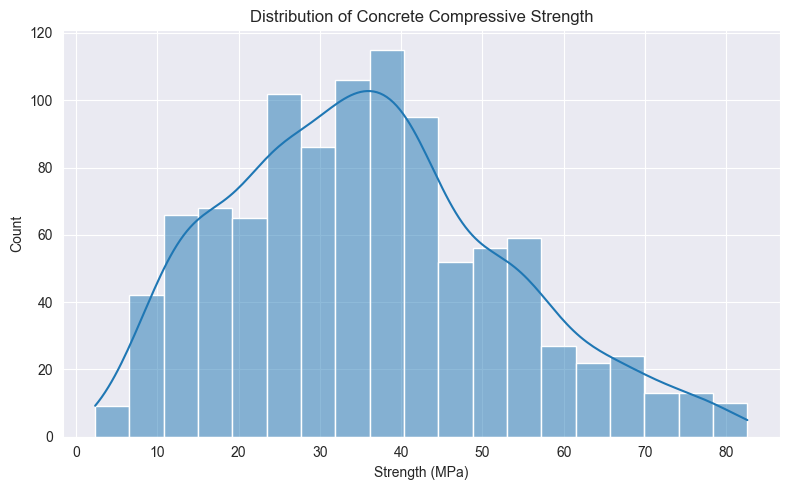

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(df["concrete_strength"], kde=True)
plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Strength (MPa)")
plt.tight_layout()
plt.show()


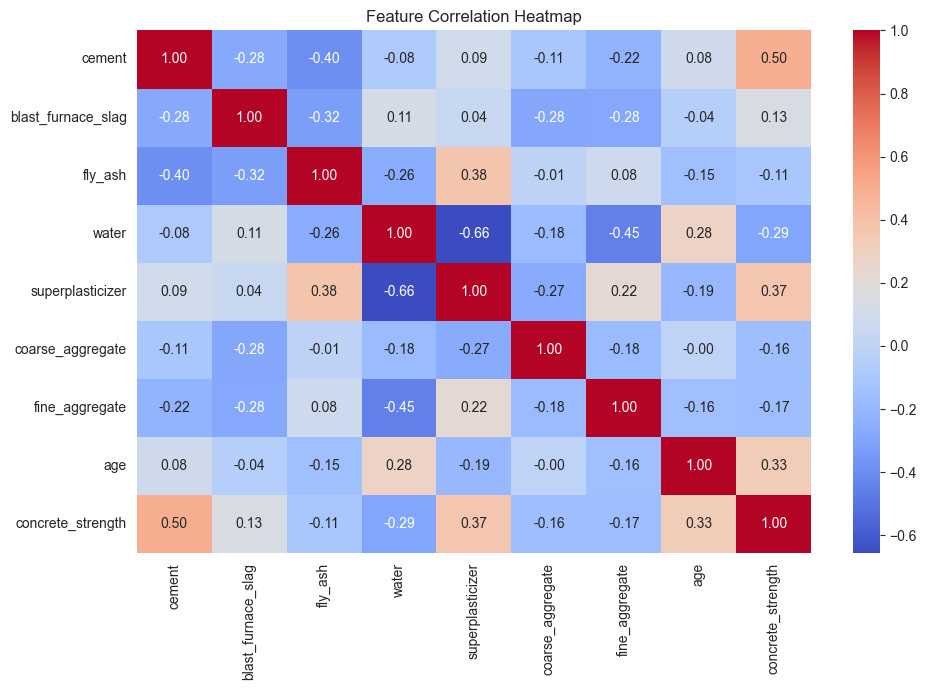

In [16]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = [
    "cement", "blast_furnace_slag", "fly_ash", "water", "superplasticizer",
    "coarse_aggregate", "fine_aggregate", "age"
]
X = df[FEATURES]
y = df["concrete_strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.1, max_iter=20000))
])
lasso_model.fit(X_train, y_train)
y_pred = lasso_model.predict(X_test)


In [18]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f} MPa")
print(f"RMSE: {rmse:.3f} MPa")
print(f"R²:   {r2:.3f}")


MAE:  7.823 MPa
RMSE: 9.819 MPa
R²:   0.626


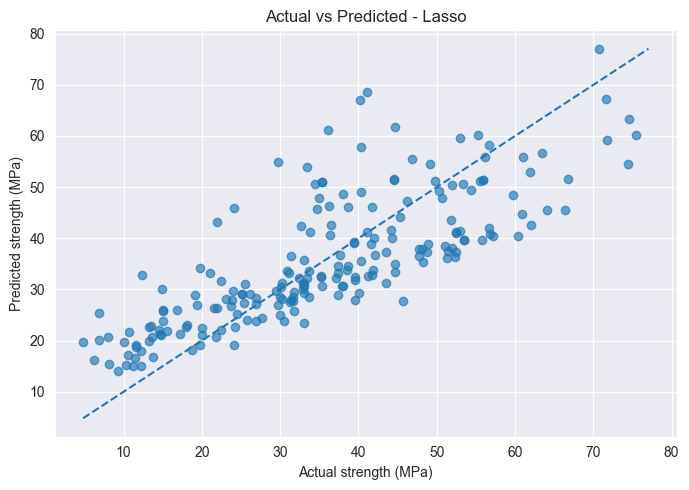

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.65)
bounds = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(bounds, bounds, "--")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Actual vs Predicted - Lasso")
plt.tight_layout()
plt.show()


,standardized_coefficient
water,-4.235677
coarse_aggregate,-0.000000
fine_aggregate,0.075828
superplasticizer,1.799018
fly_ash,3.448045
age,6.812497
blast_furnace_slag,7.396670
cement,10.718312


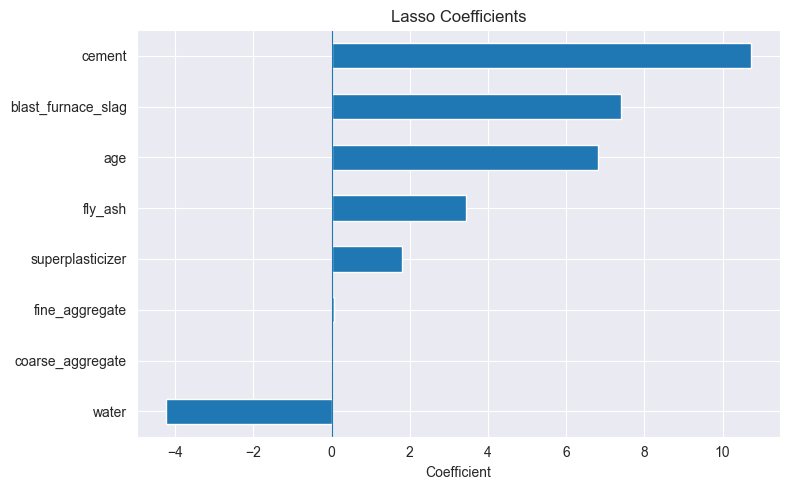

Coefficients shrunk to approximately zero: 1 of 8


In [21]:
coef = pd.Series(lasso_model.named_steps["lasso"].coef_, index=FEATURES)
display(coef.sort_values().to_frame("standardized_coefficient"))

plt.figure(figsize=(8, 5))
coef.sort_values().plot(kind="barh")
plt.axvline(0, linewidth=0.8)
plt.xlabel("Coefficient")
plt.title("Lasso Coefficients")
plt.tight_layout()
plt.show()

print("Coefficients shrunk to approximately zero:",
      int(np.isclose(coef.values, 0.0, atol=1e-8).sum()), "of", len(FEATURES))


In [23]:
alpha_values = [0.001, 0.01, 0.1, 1.0, 10.0]
rows = []

for a in alpha_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lasso", Lasso(alpha=a, max_iter=20000))
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({
        "alpha": a,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "zero_coefficients": int(np.isclose(pipe.named_steps["lasso"].coef_, 0.0, atol=1e-8).sum())
    })

pd.DataFrame(rows)


,alpha,MAE,RMSE,R2,zero_coefficients
0,0.001,7.746249,9.796431,0.627557,0
1,0.010,7.752454,9.796430,0.627557,0
2,0.100,7.823134,9.819016,0.625837,1
3,1.000,8.716247,10.600404,0.563917,2
4,10.000,13.052344,16.053557,-0.000154,8
